# Well-Log Facies Classification with a Neural Network

**Author:** Boualem Pereira · [GitHub](https://github.com/BoualemP)

## Overview

Prediction of nine lithofacies from wireline logs in the public SEG 2016 facies classification dataset. Every model is evaluated on wells held out entirely from training, and the selected model is exported for a web application that classifies a new well from a CSV file.

This project continues [Well-Log Machine Learning from Scratch](https://github.com/BoualemP/well-log-ml-from-scratch), which separated marine from non-marine intervals in the same dataset with linear models. It moves to the full nine-facies problem and follows that project's next steps: depth-context features and non-linear models.

| Model | Role |
|---|---|
| Majority class | Benchmark |
| Logistic regression | Linear baseline |
| Gradient boosting | Non-linear tree-based alternative |
| Neural network (Keras) | Main candidate |

1. Inspection of the raw data and decisions on the wells and logs to use.
2. Preparation: capping of extreme values and depth-context features from neighbouring samples.
3. Exploratory analysis of the facies and logs.
4. Tuning of each model by cross-validation with one training well held out at a time.
5. Final evaluation on two test wells never used for tuning.
6. Export of the model, its settings and two demonstration wells for the web application.

## 1. Setup

### 1.1 Libraries and constants

In [1]:
import json
import os
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # hide TensorFlow start-up messages
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"  # run on the CPU without probing for a GPU

import keras
import matplotlib.pyplot as plt
import numpy as np
import onnxruntime as ort
import pandas as pd
import seaborn as sns
import tensorflow as tf
import tf2onnx
from matplotlib.colors import ListedColormap
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)
print("TensorFlow", tf.__version__, "· Keras", keras.__version__)

DATA_PATH = Path("data") / "facies_vectors.csv"
EXPORT_DIR = Path("export")                      # files handed to the web application
LOGS = ["GR", "ILD_log10", "DeltaPHI", "PHIND", "PE"]
TEST_WELLS = ["NEWBY", "SHANKLE"]                # held out until the final evaluation
WINDOW = 5                                       # samples in the depth-context window (section 3)
SEED = 42

# Facies codes as documented with the dataset
FACIES = {1: "SS", 2: "CSiS", 3: "FSiS", 4: "SiSh", 5: "MS", 6: "WS", 7: "D", 8: "PS", 9: "BS"}
FACIES_COLORS = ["#F4D03F", "#F5B041", "#DC7633", "#6E2C00", "#1B4F72",
                 "#2E86C1", "#AED6F1", "#A569BD", "#196F3D"]

TensorFlow 2.22.0-rc0 · Keras 3.16.0.dev2026111503


### 1.2 Functions

In [2]:
def cap_logs(data, low, high):
    # Section 3: clip each log to limits learned on the training wells.
    out = data.copy()
    out[LOGS] = out[LOGS].clip(low, high, axis=1)
    return out


def add_context(data, window=WINDOW):
    # Section 3: describe each sample with its neighbours in the same well.
    out = data.sort_values(["Well Name", "Depth"]).copy()
    by_well = out.groupby("Well Name")
    for log in LOGS:
        out[f"{log}_grad"] = by_well[log].diff().fillna(0.0)
        out[f"{log}_mean"] = by_well[log].transform(
            lambda s: s.rolling(window, center=True, min_periods=1).mean())
    return out


def scores(y_true, y_pred):
    # Sections 5 and 6: accuracy and macro F1 (every facies weighs the same).
    return {"accuracy": accuracy_score(y_true, y_pred),
            "macro F1": f1_score(y_true, y_pred, average="macro")}


def cv_by_well(make_model, data, features):
    # Section 5: train on all training wells but one, score on the one left out.
    rows = []
    for well in sorted(data["Well Name"].unique()):
        fit_part = data[data["Well Name"] != well]
        held_out = data[data["Well Name"] == well]
        model = make_model()
        model.fit(fit_part[features].to_numpy(), fit_part["Facies"].to_numpy())
        rows.append({"held-out well": well,
                     **scores(held_out["Facies"], model.predict(held_out[features].to_numpy()))})
    return pd.DataFrame(rows).set_index("held-out well")


class FaciesNetwork:
    # Section 5.4: fully connected network on standardised inputs.
    # The mean and standard deviation are kept outside the network and exported with it (section 7).
    def __init__(self, units=64, dropout=0.2, epochs=60, batch_size=32):
        self.units, self.dropout = units, dropout
        self.epochs, self.batch_size = epochs, batch_size

    def fit(self, X, y):
        keras.utils.set_random_seed(SEED)
        self.mean, self.std = X.mean(axis=0), X.std(axis=0)
        self.model = keras.Sequential([
            keras.Input(shape=(X.shape[1],), name="features"),
            keras.layers.Dense(self.units, activation="relu"),
            keras.layers.Dropout(self.dropout),
            keras.layers.Dense(self.units // 2, activation="relu"),
            keras.layers.Dropout(self.dropout),
            keras.layers.Dense(len(FACIES), activation="softmax"),
        ])
        self.model.compile(optimizer=keras.optimizers.Adam(1e-3),
                           loss="sparse_categorical_crossentropy")
        self.history = self.model.fit(self.standardise(X), y - 1, epochs=self.epochs,
                                      batch_size=self.batch_size, verbose=0)
        return self

    def standardise(self, X):
        return ((X - self.mean) / self.std).astype("float32")

    def predict_proba(self, X):
        return self.model.predict(self.standardise(X), verbose=0)

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1) + 1


def plot_well(well, columns, title):
    # Section 6: log display with facies columns, as on a well-log plot.
    curves = ["GR", "ILD_log10", "PHIND", "PE"]
    fig, axes = plt.subplots(1, len(curves) + len(columns), sharey=True,
                             figsize=(2 * (len(curves) + len(columns)), 8))
    for ax, log in zip(axes, curves):
        ax.plot(well[log], well["Depth"], lw=0.8, color="k")
        ax.set_title(log)
    cmap = ListedColormap(FACIES_COLORS)
    extent = [0, 1, well["Depth"].max(), well["Depth"].min()]
    for ax, col in zip(axes[len(curves):], columns):
        ax.imshow(well[[col]].to_numpy(), aspect="auto", cmap=cmap, vmin=0.5, vmax=9.5,
                  extent=extent, interpolation="nearest")
        ax.set_title(col)
        ax.set_xticks([])
    axes[0].set_ylim(well["Depth"].max(), well["Depth"].min())
    axes[0].set_ylabel("Depth (ft)")
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FACIES_COLORS]
    fig.legend(handles, FACIES.values(), loc="lower center", ncol=9)
    fig.suptitle(title)
    plt.tight_layout(rect=[0, 0.04, 1, 1])
    plt.show()

## 2. Raw Data Inspection

In [3]:
raw = pd.read_csv(DATA_PATH)
print(f"{raw.shape[0]:,} rows, {raw.shape[1]} columns")
display(raw.head())
raw.isna().sum().to_frame("missing values").T

4,149 rows, 11 columns


,Facies,Formation,Well Name,Depth,GR,ILD_log10,DeltaPHI,PHIND,PE,NM_M,RELPOS
0,3,A1 SH,SHRIMPLIN,2793.0,77.45,0.664,9.9,11.915,4.6,1,1.000
1,3,A1 SH,SHRIMPLIN,2793.5,78.26,0.661,14.2,12.565,4.1,1,0.979
2,3,A1 SH,SHRIMPLIN,2794.0,79.05,0.658,14.8,13.050,3.6,1,0.957
3,3,A1 SH,SHRIMPLIN,2794.5,86.10,0.655,13.9,13.115,3.5,1,0.936
4,3,A1 SH,SHRIMPLIN,2795.0,74.58,0.647,13.5,13.300,3.4,1,0.915


,Facies,Formation,Well Name,Depth,GR,ILD_log10,DeltaPHI,PHIND,PE,NM_M,RELPOS
missing values,0,0,0,0,0,0,0,0,917,0,0


Only PE has missing values. Samples and missing PE values per well:

In [4]:
raw.groupby("Well Name").agg(samples=("Depth", "size"),
                             missing_PE=("PE", lambda s: s.isna().sum()))

,samples,missing_PE
Well Name,,
ALEXANDER D,466,466
CHURCHMAN BIBLE,404,0
CROSS H CATTLE,501,0
KIMZEY A,439,439
LUKE G U,461,0
NEWBY,463,0
NOLAN,415,0
Recruit F9,80,12
SHANKLE,449,0


Number of samples of each facies in each well:

In [5]:
pd.crosstab(raw["Well Name"], raw["Facies"], margins=True)

Facies,1,2,3,4,5,6,7,8,9,All
Well Name,,,,,,,,,,
ALEXANDER D,0,117,91,44,26,69,16,98,5,466
CHURCHMAN BIBLE,8,56,51,13,30,87,34,75,50,404
CROSS H CATTLE,158,142,47,25,28,31,2,68,0,501
KIMZEY A,9,85,74,43,53,51,27,90,7,439
LUKE G U,0,117,129,35,2,84,20,74,0,461
NEWBY,0,98,80,58,28,96,16,56,31,463
NOLAN,4,118,68,28,47,30,4,116,0,415
Recruit F9,0,0,0,0,0,0,0,0,80,80
SHANKLE,89,89,117,7,19,71,17,40,0,449


Recruit F9 contains only facies 9. Facies 1 (SS) is concentrated in two wells, CROSS H CATTLE (158 samples) and SHANKLE (89); the other wells have at most 9 samples of it.

Ranges of the logs:

In [6]:
raw[LOGS].describe(percentiles=[0.005, 0.5, 0.995]).T

,count,mean,std,min,0.5%,50%,99.5%,max
GR,4149.0,64.934,30.303,10.149,14.400,64.990,217.433,361.150
ILD_log10,4149.0,0.660,0.253,-0.026,0.031,0.639,1.436,1.800
DeltaPHI,4149.0,4.402,5.275,-21.832,-16.000,4.300,17.205,19.312
PHIND,4149.0,13.201,7.133,0.550,2.934,12.020,44.797,84.400
PE,3232.0,3.725,0.896,0.200,1.788,3.551,6.422,8.094


**Findings and decisions**

| Finding | Decision |
|---|---|
| ALEXANDER D and KIMZEY A have no PE log | Exclude: PE is an input of every model |
| Recruit F9 contains a single facies (9) | Exclude: it does not describe a full well |
| The 12 other missing PE values are all in Recruit F9 | Removed with Recruit F9 |
| GR and PHIND maxima (361 and 84) far above their 99.5th percentiles | Cap every log at the 0.5th and 99.5th percentiles of the training wells |
| Facies counts differ strongly between facies and between wells | Report macro F1 next to accuracy |

## 3. Preparation and Data Split

In [7]:
kept = raw[~raw["Well Name"].isin(["ALEXANDER D", "KIMZEY A", "Recruit F9"])]
train = kept[~kept["Well Name"].isin(TEST_WELLS)]
test = kept[kept["Well Name"].isin(TEST_WELLS)]

CAP_LOW, CAP_HIGH = train[LOGS].quantile(0.005), train[LOGS].quantile(0.995)
train = add_context(cap_logs(train, CAP_LOW, CAP_HIGH))
test = add_context(cap_logs(test, CAP_LOW, CAP_HIGH))

FEATURES = (LOGS + ["NM_M", "RELPOS"]
            + [f"{log}_{kind}" for log in LOGS for kind in ("grad", "mean")])
print(len(FEATURES), "features:", ", ".join(FEATURES))
pd.DataFrame({"wells": [train["Well Name"].nunique(), test["Well Name"].nunique()],
              "samples": [len(train), len(test)],
              "missing values": [train[FEATURES].isna().sum().sum(), test[FEATURES].isna().sum().sum()]},
             index=["train", "test"])

17 features: GR, ILD_log10, DeltaPHI, PHIND, PE, NM_M, RELPOS, GR_grad, GR_mean, ILD_log10_grad, ILD_log10_mean, DeltaPHI_grad, DeltaPHI_mean, PHIND_grad, PHIND_mean, PE_grad, PE_mean


,wells,samples,missing values
train,5,2252,0
test,2,912,0


No missing values remain in the 17 features.

Capping limits learned on the training wells and the number of training values changed:

In [8]:
original = kept.loc[train.index, LOGS]
pd.DataFrame({"lower cap": CAP_LOW, "upper cap": CAP_HIGH,
              "values capped": ((original < CAP_LOW) | (original > CAP_HIGH)).sum()})

,lower cap,upper cap,values capped
GR,14.463,218.706,24
ILD_log10,-0.001,1.267,24
DeltaPHI,-16.382,16.149,24
PHIND,2.928,47.459,24
PE,1.647,6.307,24


## 4. Exploratory Analysis

Share of each facies in the training and test wells:

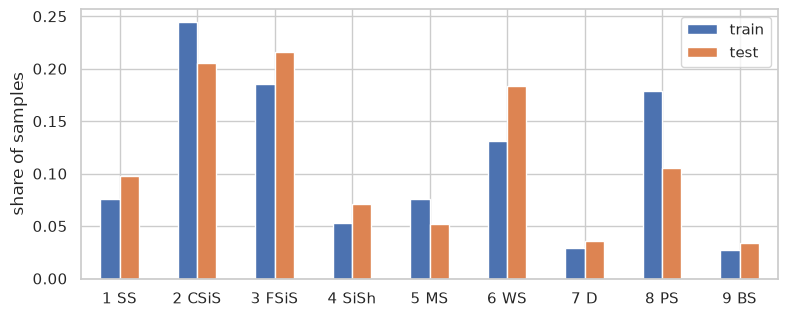

,train,test
1 SS,0.075,0.098
2 CSiS,0.245,0.205
3 FSiS,0.186,0.216
4 SiSh,0.053,0.071
5 MS,0.075,0.052
6 WS,0.131,0.183
7 D,0.029,0.036
8 PS,0.179,0.105
9 BS,0.028,0.034


In [9]:
shares = pd.DataFrame({"train": train["Facies"].value_counts(normalize=True),
                       "test": test["Facies"].value_counts(normalize=True)}).sort_index()
shares.index = [f"{k} {FACIES[k]}" for k in shares.index]
ax = shares.plot.bar(figsize=(9, 3.5), rot=0, ylabel="share of samples")
plt.show()
shares

The test wells contain fewer PS (0.105 against 0.179) and more WS (0.183 against 0.131) than the training wells.

Distribution of each log by facies in the training wells:

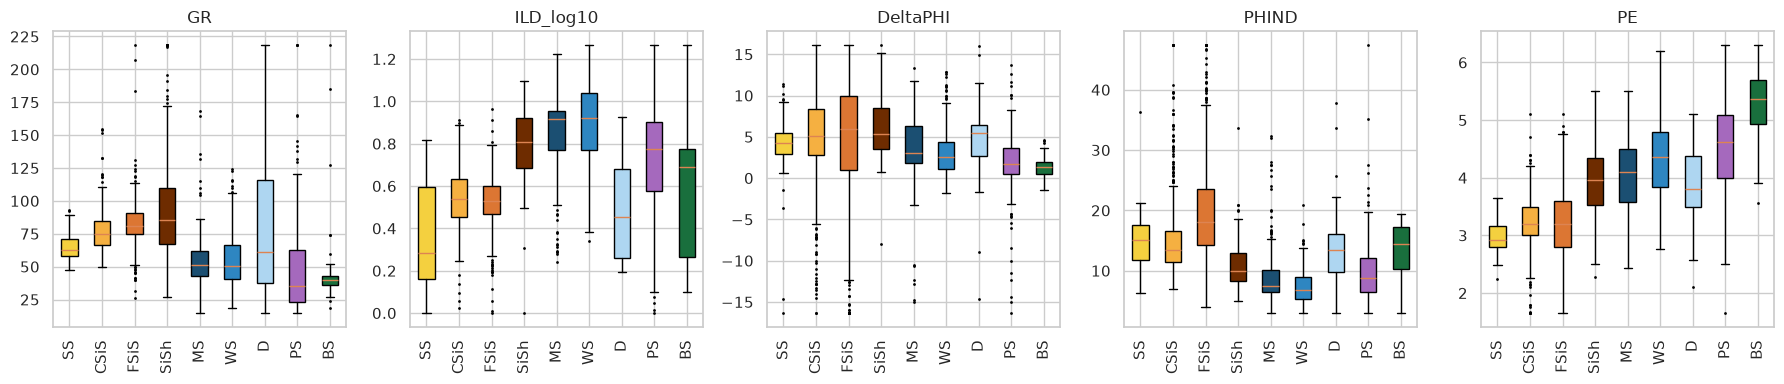

,GR,ILD_log10,DeltaPHI,PHIND,PE
Facies,,,,,
SS,62.945,0.284,4.200,15.175,2.926
CSiS,75.020,0.540,5.100,13.406,3.200
FSiS,81.015,0.530,6.000,18.100,3.200
SiSh,85.680,0.810,5.300,10.035,3.962
MS,51.020,0.914,3.054,7.455,4.107
WS,50.469,0.923,2.612,6.819,4.365
D,61.313,0.452,5.443,13.450,3.800
PS,35.188,0.773,1.698,8.813,4.623
BS,40.141,0.692,1.397,14.352,5.372


In [10]:
fig, axes = plt.subplots(1, len(LOGS), figsize=(18, 4))
for ax, log in zip(axes, LOGS):
    groups = [train.loc[train["Facies"] == k, log] for k in FACIES]
    boxes = ax.boxplot(groups, patch_artist=True, flierprops={"markersize": 1})
    for patch, color in zip(boxes["boxes"], FACIES_COLORS):
        patch.set_facecolor(color)
    ax.set_xticks(range(1, len(FACIES) + 1), FACIES.values(), rotation=90)
    ax.set_title(log)
plt.tight_layout()
plt.show()
train.groupby("Facies")[LOGS].median().rename(index=FACIES)

No single log separates the nine facies. PE has medians of 2.9 to 3.2 in SS, CSiS and FSiS and of 3.8 to 5.4 in the six other facies; GR is lowest in PS and BS. The ranges of neighbouring facies overlap strongly.

## 5. Modelling

Each model is scored by cross-validation over the five training wells: in turn, one well is left out, the model is trained on the other four and scored on the left-out well. The test wells are not used in this section.

### 5.1 Benchmark: majority class

In [11]:
class MajorityClass:
    def fit(self, X, y):
        self.value = pd.Series(y).mode()[0]
        return self

    def predict(self, X):
        return np.full(len(X), self.value)


cv_results = {"Majority class": cv_by_well(MajorityClass, train, FEATURES)}
cv_results["Majority class"]

,accuracy,macro F1
held-out well,,
CHURCHMAN BIBLE,0.139,0.027
CROSS H CATTLE,0.283,0.055
LUKE G U,0.254,0.058
NOLAN,0.284,0.055
SHRIMPLIN,0.251,0.050


The majority class scores a macro F1 of 0.03 to 0.06 on the left-out wells: the reference that any useful model must clearly exceed.

### 5.2 Logistic regression

In [12]:
logistic_grid = {}
for C in [0.01, 0.1, 1, 10]:
    logistic_grid[C] = cv_by_well(
        lambda: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000)),
        train, FEATURES).mean()
logistic_grid = pd.DataFrame(logistic_grid).T.rename_axis("C")
logistic_grid

,accuracy,macro F1
C,,
0.01,0.466,0.280
0.10,0.463,0.317
1.00,0.447,0.311
10.00,0.433,0.301


In [13]:
BEST_C = logistic_grid["macro F1"].idxmax()
cv_results["Logistic regression"] = cv_by_well(
    lambda: make_pipeline(StandardScaler(), LogisticRegression(C=BEST_C, max_iter=5000)),
    train, FEATURES)
print("Selected C:", BEST_C)
cv_results["Logistic regression"]

Selected C: 0.1


,accuracy,macro F1
held-out well,,
CHURCHMAN BIBLE,0.426,0.308
CROSS H CATTLE,0.367,0.292
LUKE G U,0.447,0.332
NOLAN,0.520,0.303
SHRIMPLIN,0.556,0.349


C = 0.1 gives the best mean macro F1 (0.317), with 0.29 to 0.35 depending on the left-out well.

### 5.3 Gradient boosting

In [14]:
boosting_grid = {}
for depth in [3, 6]:
    for rate in [0.03, 0.1]:
        boosting_grid[(depth, rate)] = cv_by_well(
            lambda: HistGradientBoostingClassifier(max_depth=depth, learning_rate=rate,
                                                   max_iter=200, random_state=SEED),
            train, FEATURES).mean()
boosting_grid = pd.DataFrame(boosting_grid).T.rename_axis(["max depth", "learning rate"])
boosting_grid

accuracy  macro F1
max depth learning rate                    
3         0.03              0.451     0.324
          0.10              0.448     0.316
6         0.03              0.454     0.338
          0.10              0.449     0.319

In [15]:
BEST_DEPTH, BEST_RATE = boosting_grid["macro F1"].idxmax()
cv_results["Gradient boosting"] = cv_by_well(
    lambda: HistGradientBoostingClassifier(max_depth=BEST_DEPTH, learning_rate=BEST_RATE,
                                           max_iter=200, random_state=SEED),
    train, FEATURES)
print("Selected max depth and learning rate:", BEST_DEPTH, BEST_RATE)
cv_results["Gradient boosting"]

Selected max depth and learning rate: 6 0.03


,accuracy,macro F1
held-out well,,
CHURCHMAN BIBLE,0.403,0.295
CROSS H CATTLE,0.305,0.269
LUKE G U,0.475,0.368
NOLAN,0.508,0.289
SHRIMPLIN,0.577,0.470


A maximum depth of 6 with a learning rate of 0.03 is the best setting (0.338), but the four settings are within 0.022 of each other. The left-out well matters more than the setting: from 0.27 (CROSS H CATTLE) to 0.47 (SHRIMPLIN).

### 5.4 Neural network

Two hidden layers (the second with half the units of the first) with dropout. The grid varies the width and the dropout rate.

In [16]:
network_grid = {}
for units in [32, 64]:
    for dropout in [0.0, 0.3]:
        network_grid[(units, dropout)] = cv_by_well(
            lambda: FaciesNetwork(units=units, dropout=dropout), train, FEATURES).mean()
network_grid = pd.DataFrame(network_grid).T.rename_axis(["units", "dropout"])
network_grid

accuracy  macro F1
units dropout                    
32    0.0         0.418     0.280
      0.3         0.474     0.305
64    0.0         0.410     0.290
      0.3         0.459     0.312

In [17]:
BEST_UNITS, BEST_DROPOUT = network_grid["macro F1"].idxmax()
cv_results["Neural network"] = cv_by_well(
    lambda: FaciesNetwork(units=int(BEST_UNITS), dropout=BEST_DROPOUT), train, FEATURES)
print("Selected units and dropout:", int(BEST_UNITS), BEST_DROPOUT)
cv_results["Neural network"]

Selected units and dropout: 64 0.3


,accuracy,macro F1
held-out well,,
CHURCHMAN BIBLE,0.450,0.332
CROSS H CATTLE,0.351,0.285
LUKE G U,0.477,0.351
NOLAN,0.533,0.299
SHRIMPLIN,0.484,0.295


Dropout improves both widths (0.280 to 0.305 with 32 units, 0.290 to 0.312 with 64 units); 64 units with a dropout rate of 0.3 is selected.

Training loss of the selected network on all five training wells:

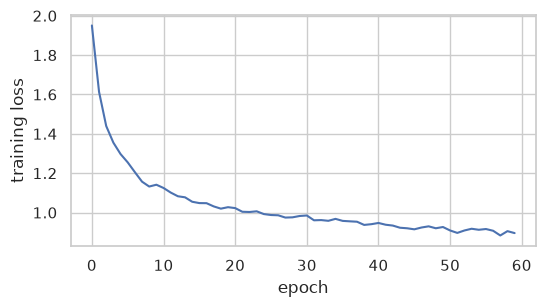

final training loss: 0.896


In [18]:
network = FaciesNetwork(units=int(BEST_UNITS), dropout=BEST_DROPOUT)
network.fit(train[FEATURES].to_numpy(), train["Facies"].to_numpy())
plt.figure(figsize=(6, 3))
plt.plot(network.history.history["loss"])
plt.xlabel("epoch")
plt.ylabel("training loss")
plt.show()
print("final training loss:", round(network.history.history["loss"][-1], 3))

The loss falls quickly over the first 20 epochs and flattens afterwards, reaching 0.896 at epoch 60.

### 5.5 Comparison by cross-validation

In [19]:
cv_summary = pd.DataFrame({name: res.mean() for name, res in cv_results.items()}).T
cv_spread = pd.DataFrame({name: res["macro F1"].agg(["min", "max"]) for name, res in cv_results.items()}).T
cv_summary.join(cv_spread.add_prefix("macro F1 "))

,accuracy,macro F1,macro F1 min,macro F1 max
Majority class,0.242,0.049,0.027,0.058
Logistic regression,0.463,0.317,0.292,0.349
Gradient boosting,0.454,0.338,0.269,0.470
Neural network,0.459,0.312,0.285,0.351


The three trained models are within 0.026 of each other in mean macro F1 (0.312 to 0.338), less than the variation between left-out wells for each of them: cross-validation does not separate them. All three are far above the majority class.

**Model for the web application.** As the three models perform alike, the neural network is selected for practical reasons: it converts to ONNX and runs without TensorFlow (section 7). The test wells check that this choice does not lose against the alternatives.

## 6. Evaluation on the Test Wells

Each model is trained on the five training wells with its selected settings and applied to the two test wells.

In [20]:
final_models = {
    "Majority class": MajorityClass(),
    "Logistic regression": make_pipeline(StandardScaler(),
                                         LogisticRegression(C=BEST_C, max_iter=5000)),
    "Gradient boosting": HistGradientBoostingClassifier(max_depth=BEST_DEPTH, learning_rate=BEST_RATE,
                                                        max_iter=200, random_state=SEED),
}
for model in final_models.values():
    model.fit(train[FEATURES].to_numpy(), train["Facies"].to_numpy())
final_models["Neural network"] = network        # already trained in section 5.4

test_rows = {}
for name, model in final_models.items():
    test[name] = model.predict(test[FEATURES].to_numpy())
    test_rows[name] = {"all test wells": scores(test["Facies"], test[name])["macro F1"],
                       **{well: scores(part["Facies"], part[name])["macro F1"]
                          for well, part in test.groupby("Well Name")},
                       "accuracy": scores(test["Facies"], test[name])["accuracy"]}
pd.DataFrame(test_rows).T.rename(columns=lambda c: c if c == "accuracy" else f"macro F1 {c}")

,macro F1 all test wells,macro F1 NEWBY,macro F1 SHANKLE,accuracy
Majority class,0.038,0.044,0.041,0.205
Logistic regression,0.399,0.352,0.463,0.509
Gradient boosting,0.396,0.363,0.418,0.493
Neural network,0.446,0.466,0.404,0.476


On the test wells the neural network has the highest macro F1 (0.446, against 0.399 and 0.396), while logistic regression has the highest accuracy (0.509 against 0.476). The best model differs between the two wells: the network in NEWBY (0.466), logistic regression in SHANKLE (0.463).

Confusion matrix of the neural network on the test wells (rows: true facies, columns: predicted), as a share of each true facies:

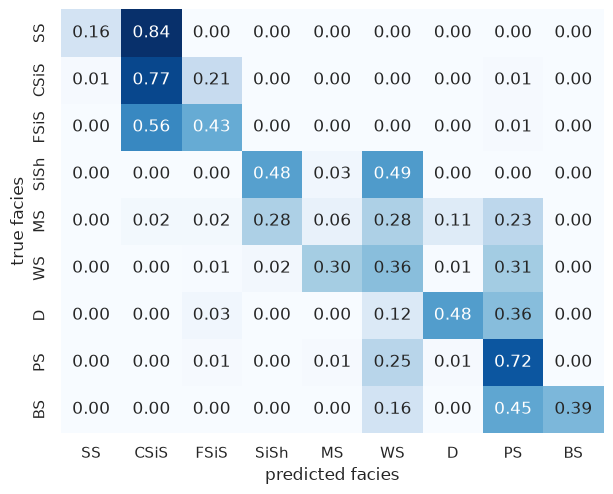

,SS,CSiS,FSiS,SiSh,MS,WS,D,PS,BS
share correctly classified,0.157,0.77,0.431,0.477,0.064,0.359,0.485,0.719,0.387


In [21]:
cm = confusion_matrix(test["Facies"], test["Neural network"], labels=list(FACIES), normalize="true")
cm = pd.DataFrame(cm, index=FACIES.values(), columns=FACIES.values())
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", cbar=False)
plt.ylabel("true facies")
plt.xlabel("predicted facies")
plt.show()
pd.Series(np.diag(cm), index=cm.index, name="share correctly classified").to_frame().T

Most errors fall between facies with adjacent codes: 84 % of SS and 56 % of FSiS are predicted as CSiS, half of SiSh is predicted as WS, and WS is split between MS (0.30), WS (0.36) and PS (0.31). MS is almost never recognised (0.06).

Logs, true facies and predicted facies in each test well:

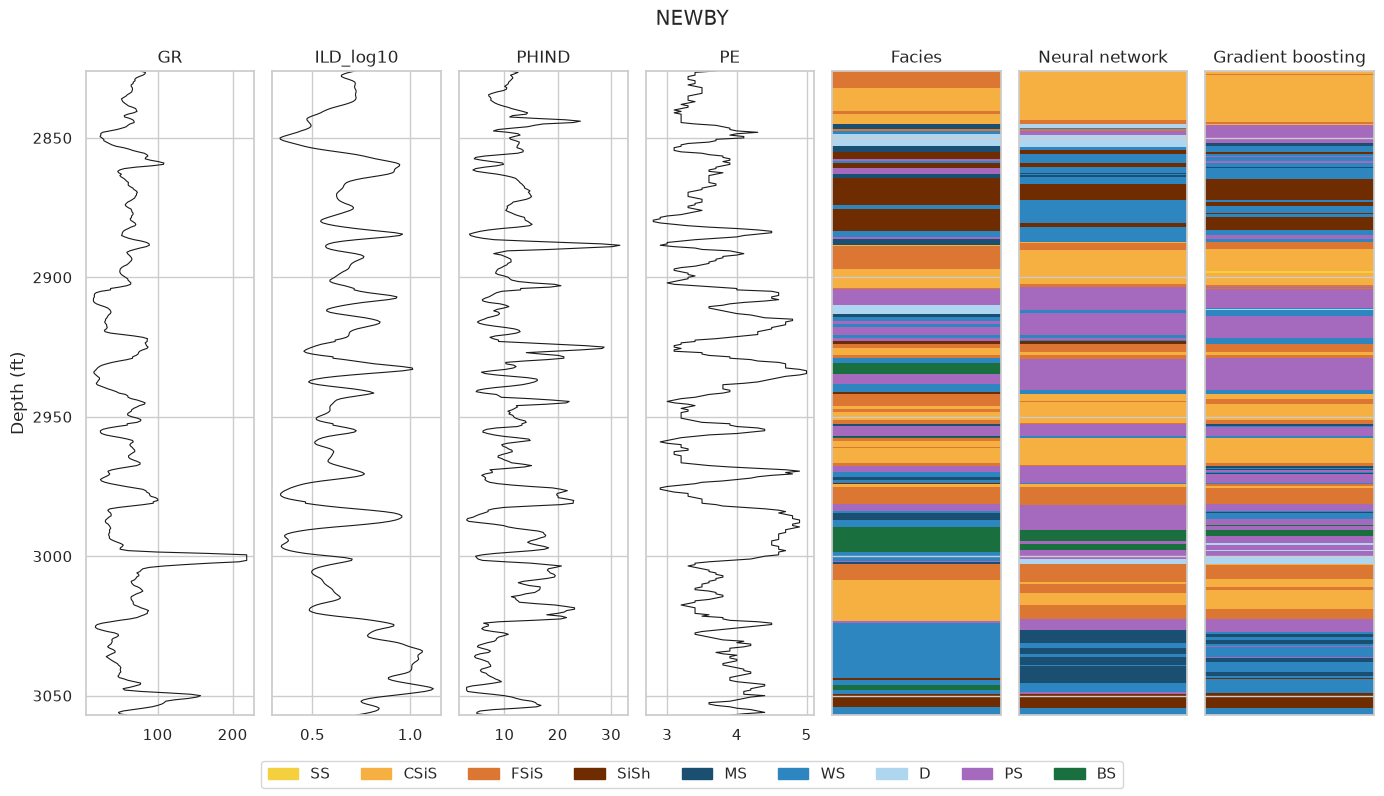

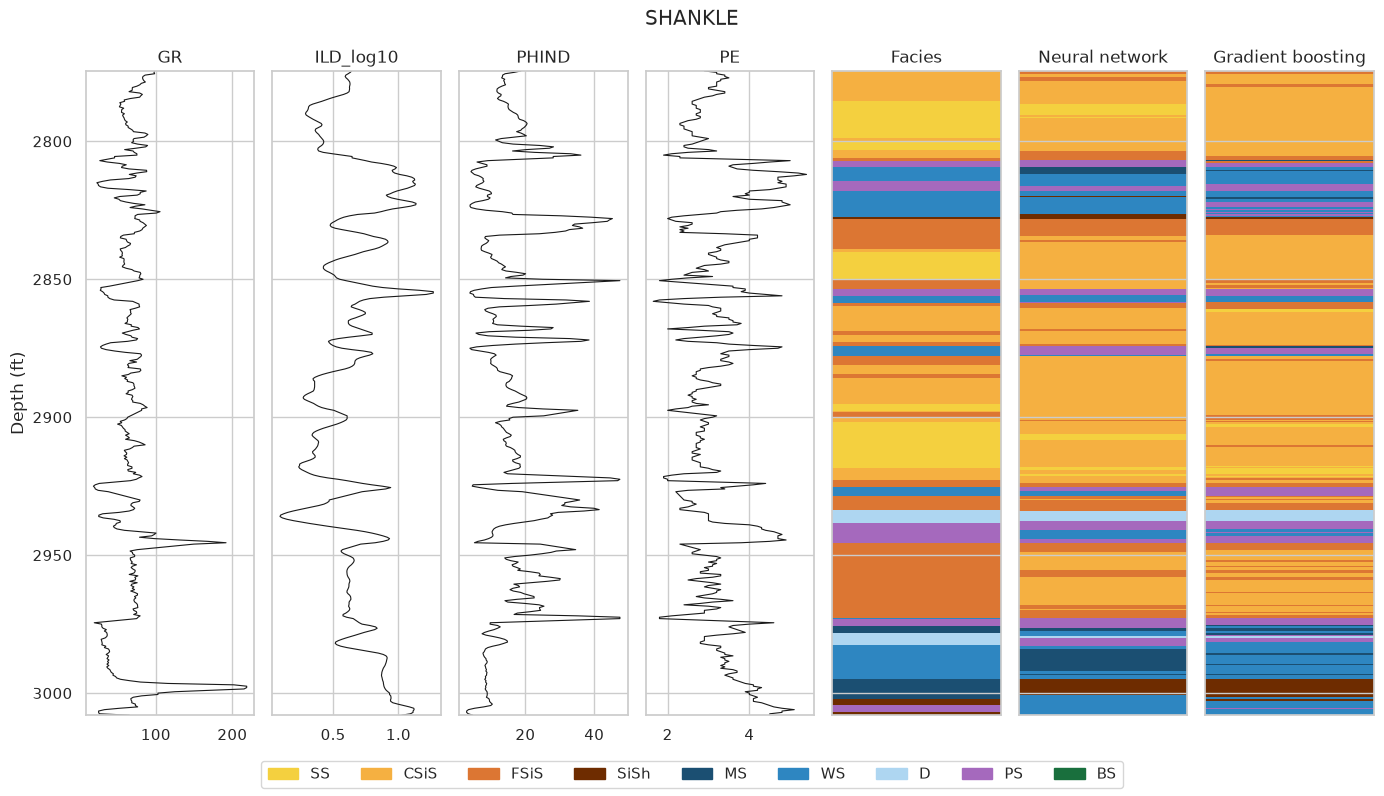

In [22]:
for well_name, well in test.groupby("Well Name"):
    plot_well(well, ["Facies", "Neural network", "Gradient boosting"], well_name)

Number of facies changes between consecutive samples in each column, a measure of how fragmented each column is:

In [23]:
test.groupby("Well Name")[["Facies", "Neural network", "Gradient boosting", "Logistic regression"]].agg(
    lambda s: int((s.diff().fillna(0) != 0).sum()))

,Facies,Neural network,Gradient boosting,Logistic regression
Well Name,,,,
NEWBY,84,70,101,57
SHANKLE,47,68,109,70


Gradient boosting changes facies about twice as often as the true columns (101 and 109 changes, against 84 and 47). The neural network and logistic regression are less fragmented (57 to 70 changes), although SHANKLE is still more fragmented than its true column.

## 7. Export for the Web Application

The network is converted to ONNX, a format that can run without TensorFlow. The ONNX model receives standardised features, so the mean and standard deviation of each feature are exported with it. The conversion is checked by comparing its probabilities with those of the Keras model on the test wells.

In [24]:
EXPORT_DIR.mkdir(exist_ok=True)
signature = (tf.TensorSpec((None, len(FEATURES)), tf.float32, name="features"),)


@tf.function(input_signature=signature)
def serve(features):
    return network.model(features, training=False)


tf2onnx.convert.from_function(serve, input_signature=signature, opset=17,
                              output_path=str(EXPORT_DIR / "facies_model.onnx"))

session = ort.InferenceSession(str(EXPORT_DIR / "facies_model.onnx"))
X_test = test[FEATURES].to_numpy()
onnx_proba = session.run(None, {session.get_inputs()[0].name: network.standardise(X_test)})[0]
keras_proba = network.predict_proba(X_test)
print("largest probability difference:", float(np.abs(onnx_proba - keras_proba).max()))
print("identical predicted facies:", bool((onnx_proba.argmax(1) == keras_proba.argmax(1)).all()))

largest probability difference: 2.980232238769531e-07
identical predicted facies: True


Settings the application needs to rebuild the features of a new well, and the two test wells as demonstration files:

In [25]:
settings = {
    "logs": LOGS,
    "other_inputs": ["NM_M", "RELPOS"],
    "features": FEATURES,
    "context_window": WINDOW,
    "cap_low": CAP_LOW.round(4).to_dict(),
    "cap_high": CAP_HIGH.round(4).to_dict(),
    "feature_mean": dict(zip(FEATURES, network.mean.tolist())),
    "feature_std": dict(zip(FEATURES, network.std.tolist())),
    "facies": {str(k): v for k, v in FACIES.items()},
    "facies_colors": FACIES_COLORS,
}
(EXPORT_DIR / "settings.json").write_text(json.dumps(settings, indent=2))

demo_columns = ["Well Name", "Depth"] + LOGS + ["NM_M", "RELPOS", "Facies"]
for well_name in TEST_WELLS:
    demo = kept[kept["Well Name"] == well_name][demo_columns]
    demo.to_csv(EXPORT_DIR / f"demo_{well_name.lower()}.csv", index=False)

pd.DataFrame({"file": [p.name for p in sorted(EXPORT_DIR.iterdir())],
              "size (kB)": [round(p.stat().st_size / 1024, 1) for p in sorted(EXPORT_DIR.iterdir())]})

,file,size (kB)
0,demo_newby.csv,21.8
1,demo_shankle.csv,22.5
2,facies_model.onnx,15.5
3,settings.json,2.3


## 8. Conclusions

**Results**

| Model | Macro F1, cross-validation (mean, range over wells) | Macro F1, test wells | Accuracy, test wells |
|---|---|---|---|
| Majority class | 0.049 (0.03–0.06) | 0.038 | 0.205 |
| Logistic regression | 0.317 (0.29–0.35) | 0.399 | 0.509 |
| Gradient boosting | 0.338 (0.27–0.47) | 0.396 | 0.493 |
| **Neural network** | 0.312 (0.29–0.35) | **0.446** | 0.476 |

**Key findings**

- The three trained models score six to seven times the majority-class benchmark in cross-validation, but cross-validation does not separate them: their differences (0.026) are smaller than the variation between wells.
- On the test wells the neural network has the best macro F1 (0.446) and logistic regression the best accuracy (0.509); the best model differs between the two wells.
- Most errors fall between facies with adjacent codes (CSiS / FSiS, WS / PS); SS is rarely recognised, as almost all its training samples come from a single well.
- Gradient boosting produces the most fragmented facies columns (about twice as many changes as the true columns).

**Selected model:** the neural network, for the web application. The models are equivalent by cross-validation, and the network converts to a 15.5 kB ONNX file that runs without TensorFlow, with probabilities identical to the Keras model.

**Limitations and next steps**

- Five training wells is a small sample: scores vary more between wells than between models.
- Facies with few samples (SS, MS, D, BS) are poorly predicted; class weighting or more wells would help.
- Next step: the web application that loads a well from a CSV file, rebuilds the features with `settings.json` and classifies it with the ONNX model.